In [1]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

import os
os.chdir('/content/drive/MyDrive/ve/variance_analysis')

Mounted at /content/drive/


# 1D Decoding Analysis

In [2]:
!pip install -e /content/drive/MyDrive/ve/variance_analysis

!pip -q install fonttools

!ttx -l fonts/Helvetica.ttc

!sudo mkdir -p /usr/share/fonts/truetype/helvetica
!ttx -y 0 -o /usr/share/fonts/truetype/helvetica/Helvetica-Regular.ttf fonts/Helvetica.ttc
!ttx -y 1 -o /usr/share/fonts/truetype/helvetica/Helvetica-Oblique.ttf fonts/Helvetica.ttc
!ttx -y 2 -o /usr/share/fonts/truetype/helvetica/Helvetica-Bold.ttf fonts/Helvetica.ttc
!ttx -y 3 -o /usr/share/fonts/truetype/helvetica/Helvetica-BoldOblique.ttf fonts/Helvetica.ttc

!fc-cache -fv


Obtaining file:///content/drive/MyDrive/ve/variance_analysis
  Preparing metadata (setup.py) ... done
  Attempting uninstall: variance_analysis
    Found existing installation: variance_analysis 0.1.0
    Uninstalling variance_analysis-0.1.0:
      Successfully uninstalled variance_analysis-0.1.0
  Running setup.py develop for variance_analysis
ERROR: specify a font number between 0 and 5 (inclusive)
Dumping "fonts/Helvetica.ttc" to "/usr/share/fonts/truetype/helvetica/Helvetica-Regular.ttf"...
Dumping 'GlyphOrder' table...
Dumping 'head' table...
Dumping 'hhea' table...
Dumping 'maxp' table...
Dumping 'OS/2' table...
Dumping 'hmtx' table...
Dumping 'hdmx' table...
Dumping 'cmap' table...
Dumping 'fpgm' table...
Dumping 'prep' table...
Dumping 'cvt ' table...
Dumping 'loca' table...
Dumping 'glyf' table...
Dumping 'kern' table...
Dumping 'name' table...
Dumping 'post' table...
Dumping 'Zapf' table...
Dumping 'feat' table...
Dumping 'meta' table...
Dumping 'morx' table...
Dumping 'prop'

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.io import loadmat
from scipy.io.matlab._mio5_params import mat_struct
import os
from pathlib import Path
import matplotlib.font_manager as fm
import shutil

current_file_path = Path().resolve()
current_file_path

# set up matplotlib formatting too

!mkdir -p ~/.fonts
!cp fonts/Helvetica.ttc ~/.fonts/

cache_dir = os.path.join(os.path.expanduser("~"), ".cache", "matplotlib")
if os.path.exists(cache_dir):

    shutil.rmtree(cache_dir)

fm._load_fontmanager(try_read_cache=False)
plt.rcParams['font.family'] = 'Helvetica'


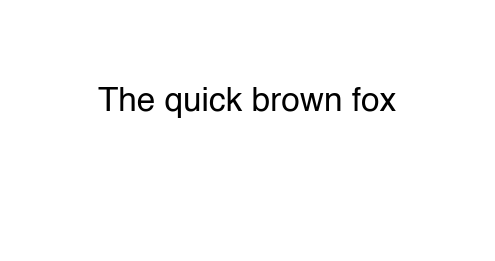

In [4]:
fig, ax = plt.subplots(figsize=(4, 2), dpi=150)
ax.text(0.5, 0.62, 'The quick brown fox', ha='center', va='center', fontsize=16)
ax.axis('off')
plt.show()


## Decode HD from Pfeiffer place cells

In [5]:

save_path = current_file_path / f'results/rodents/pfeiffer'
data_path = current_file_path / f'data/rodents/pfeiffer'

rats = [1,2,3,4]
rat_neurons = [204, 174, 79, 94]



In [ ]:
from src.pfeiffer_decode_solo import decode_solo

reload = True

for rat in rats:
    try:
      if not reload and f'errors_hd_cv0_360_all.npz' in os.listdir(save_path / f'Rat{rat}'):
        continue
    except Exception as e:
      pass

    decode_solo(
        data_path=data_path,
        save_path=save_path,
        rat=rat,
        cv_folds=4,
        save_intermediates=True
      )


Saved: figs/pfeiffer_xy_decoding_vs_chance.pdf
Saved: figs/pfeiffer_hd_decoding_vs_chance.pdf


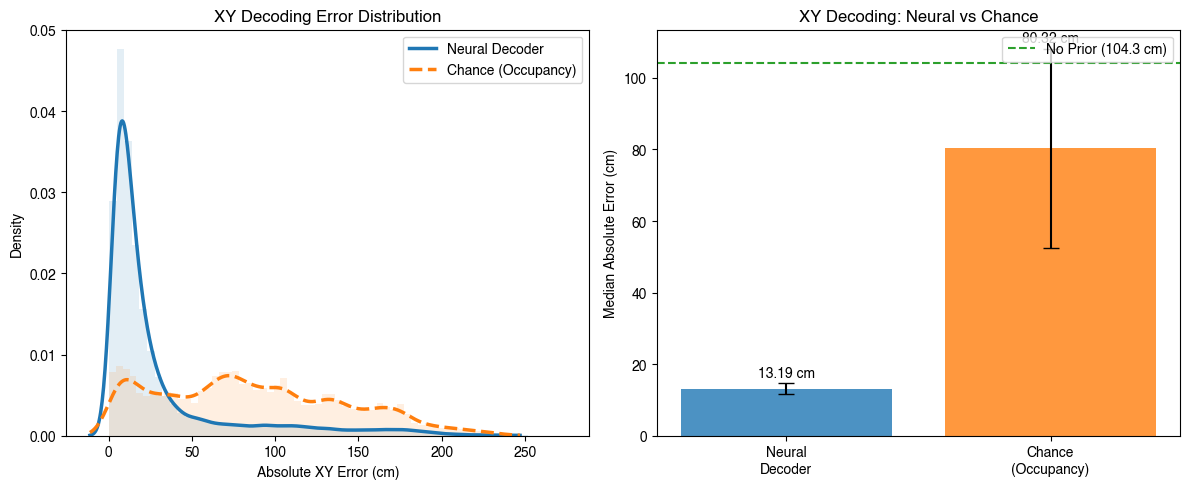

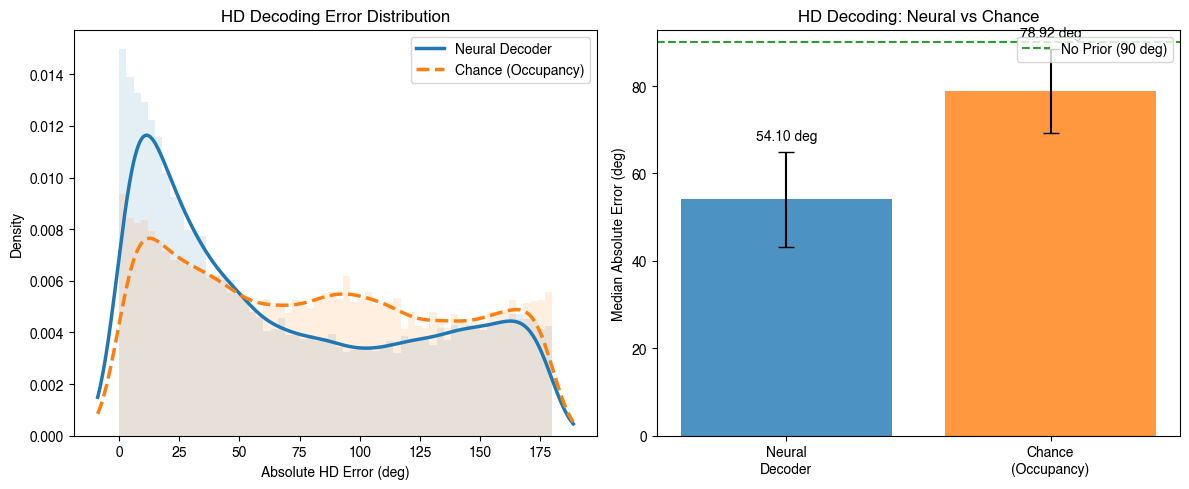

In [6]:
use_median = True  # Use median for summary stats
ARENA_SIZE_CM = 200.0
XY_GRID = 100
HD_BINS = 360
bins = 60
density = True

# No-prior chance values (uniform random guessing)
import math
sqrt2 = math.sqrt(2)
NO_PRIOR_XY_COEFF = (2 + sqrt2 + 5 * math.log(1 + sqrt2)) / 15  # ~0.5214
NO_PRIOR_XY_CM = NO_PRIOR_XY_COEFF * ARENA_SIZE_CM  # ~104.28 cm for 200cm arena
NO_PRIOR_HD_DEG = 90.0  # Expected error for uniform guessing over [0, 360)

# ============ Imports ============
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import gaussian_kde

# ============ Load data ============
xy_all = []
hd_all = []
xy_chance_all = []
hd_chance_all = []
rat_xy_native = []
rat_hd_native = []
rat_xy_chance_native = []
rat_hd_chance_native = []

for rat in rats:
    dpath = save_path / f"Rat{rat}"
    if not dpath.exists():
        continue

    # Neural decoding files
    xfiles = sorted(dpath.glob("errors_xy_cv*_*x*.npz"))
    hfiles = sorted(dpath.glob("errors_hd_cv*_360.npz"))

    # Chance decoding files
    xfiles_chance = sorted(dpath.glob("errors_xy_chance_cv*_*x*.npz"))
    hfiles_chance = sorted(dpath.glob("errors_hd_chance_cv*_360.npz"))

    # Load XY neural decoding errors
    if xfiles:
        a = np.concatenate([np.asarray(np.load(f, allow_pickle=True)["errors_cm"]).ravel() for f in xfiles])
        a = a[np.isfinite(a)]
        if a.size:
            xy_all.append(a)
            rat_xy_native.append(np.nanmedian(a) if use_median else np.nanmean(a))

    # Load XY chance decoding errors
    if xfiles_chance:
        a = np.concatenate([np.asarray(np.load(f, allow_pickle=True)["errors_cm"]).ravel() for f in xfiles_chance])
        a = a[np.isfinite(a)]
        if a.size:
            xy_chance_all.append(a)
            rat_xy_chance_native.append(np.nanmedian(a) if use_median else np.nanmean(a))

    # Load HD neural decoding errors
    if hfiles:
        b = np.concatenate([np.abs(np.asarray(np.load(f, allow_pickle=True)["errors_deg"]).ravel()) for f in hfiles])
        b = b[np.isfinite(b)]
        if b.size:
            hd_all.append(b)
            rat_hd_native.append(np.nanmedian(b) if use_median else np.nanmean(b))

    # Load HD chance decoding errors
    if hfiles_chance:
        b = np.concatenate([np.abs(np.asarray(np.load(f, allow_pickle=True)["errors_deg"]).ravel()) for f in hfiles_chance])
        b = b[np.isfinite(b)]
        if b.size:
            hd_chance_all.append(b)
            rat_hd_chance_native.append(np.nanmedian(b) if use_median else np.nanmean(b))

# Concatenate all data
all_xy = np.concatenate(xy_all) if xy_all else np.array([])
all_xy = all_xy[all_xy > 0.002]
all_hd = np.concatenate(hd_all) if hd_all else np.array([])

# Check if chance data is available
has_xy_chance = len(xy_chance_all) > 0
has_hd_chance = len(hd_chance_all) > 0

if has_xy_chance:
    all_xy_chance = np.concatenate(xy_chance_all)
    all_xy_chance = all_xy_chance[all_xy_chance > 0.002]
else:
    all_xy_chance = None
    print("Warning: XY chance decoding data not found")

if has_hd_chance:
    all_hd_chance = np.concatenate(hd_chance_all)
else:
    all_hd_chance = None
    print("Warning: HD chance decoding data not found")


# ============ Figure 1: XY Decoding ============
fig_xy, axs_xy = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: KDE comparison
# Compute plotting range robustly (use combined quantiles so both curves show well)
if all_xy.size:
    if all_xy_chance is not None and all_xy_chance.size:
        _xy_for_range = np.concatenate([all_xy, all_xy_chance])
    else:
        _xy_for_range = all_xy

    qlo, qhi = np.quantile(_xy_for_range[np.isfinite(_xy_for_range)], [0.001, 0.999])
    if not np.isfinite(qlo) or not np.isfinite(qhi) or qhi <= qlo:
        qlo, qhi = float(np.nanmin(_xy_for_range)), float(np.nanmax(_xy_for_range))

    pad = 0.05 * (qhi - qlo) if qhi > qlo else 1.0
    xs_xy = np.linspace(qlo - pad, qhi + pad, 600)

    # Optional faint histogram fill for context (comment out if you want only KDE)
    axs_xy[0].hist(all_xy, bins=bins, density=density, alpha=0.12, color="C0", edgecolor="none")
    if all_xy_chance is not None:
        axs_xy[0].hist(all_xy_chance, bins=bins, density=density, alpha=0.12, color="C1", edgecolor="none")

    kde_xy = gaussian_kde(all_xy[np.isfinite(all_xy)])
    axs_xy[0].plot(xs_xy, kde_xy(xs_xy), color="C0", linewidth=2.5, label="Neural Decoder")

    if all_xy_chance is not None and np.isfinite(all_xy_chance).any() and all_xy_chance.size > 1:
        kde_xy_ch = gaussian_kde(all_xy_chance[np.isfinite(all_xy_chance)])
        axs_xy[0].plot(xs_xy, kde_xy_ch(xs_xy), color="C1", linewidth=2.5, linestyle="--",
                       label="Chance (Occupancy)")
else:
    print("Warning: No XY neural decoding data found")

axs_xy[0].set_xlabel("Absolute XY Error (cm)")
axs_xy[0].set_ylabel("Density" if density else "Count")
axs_xy[0].set_title("XY Decoding Error Distribution")
axs_xy[0].legend()

# Subplot 2: Bar plot comparing median errors
xy_median_neural = float(np.nanmedian(all_xy)) if use_median else float(np.nanmean(all_xy))
xy_median_chance = (float(np.nanmedian(all_xy_chance)) if use_median else float(np.nanmean(all_xy_chance))) if all_xy_chance is not None else 0

# Per-rat stats for error bars
rat_xy_neural = np.array(rat_xy_native)
rat_xy_chance = np.array(rat_xy_chance_native)

xy_std_neural = float(np.nanstd(rat_xy_neural, ddof=1)) if len(rat_xy_neural) > 1 else 0
xy_std_chance = float(np.nanstd(rat_xy_chance, ddof=1)) if len(rat_xy_chance) > 1 else 0

bar_labels = ["Neural\nDecoder", "Chance\n(Occupancy)"]
bar_values = [xy_median_neural, xy_median_chance]
bar_errors = [xy_std_neural, xy_std_chance]
bar_colors = ["C0", "C1"]

bars = axs_xy[1].bar([0, 1], bar_values, yerr=bar_errors, capsize=6,
                      alpha=0.8, color=bar_colors)
axs_xy[1].set_xticks([0, 1])
axs_xy[1].set_xticklabels(bar_labels)
axs_xy[1].set_ylabel(f"{'Median' if use_median else 'Mean'} Absolute Error (cm)")
axs_xy[1].set_title("XY Decoding: Neural vs Chance")

# Add no-prior chance reference line
axs_xy[1].axhline(y=NO_PRIOR_XY_CM, color="C2", linestyle="--", linewidth=1.5,
                  label=f"No Prior ({NO_PRIOR_XY_CM:.1f} cm)")
axs_xy[1].legend(loc="upper right")

# Add value labels on bars
for i, (val, err) in enumerate(zip(bar_values, bar_errors)):
    axs_xy[1].text(i, val + err + 1, f"{val:.2f} cm",
                   ha="center", va="bottom", fontsize=10)

fig_xy.tight_layout()


# ============ Figure 2: HD Decoding ============
fig_hd, axs_hd = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: KDE comparison
if all_hd.size:
    if all_hd_chance is not None and all_hd_chance.size:
        _hd_for_range = np.concatenate([all_hd, all_hd_chance])
    else:
        _hd_for_range = all_hd

    qlo, qhi = np.quantile(_hd_for_range[np.isfinite(_hd_for_range)], [0.001, 0.999])
    if not np.isfinite(qlo) or not np.isfinite(qhi) or qhi <= qlo:
        qlo, qhi = float(np.nanmin(_hd_for_range)), float(np.nanmax(_hd_for_range))

    pad = 0.05 * (qhi - qlo) if qhi > qlo else 1.0
    xs_hd = np.linspace(qlo - pad, qhi + pad, 600)

    # Optional faint histogram fill for context (comment out if you want only KDE)
    axs_hd[0].hist(all_hd, bins=bins, density=density, alpha=0.12, color="C0", edgecolor="none")
    if all_hd_chance is not None:
        axs_hd[0].hist(all_hd_chance, bins=bins, density=density, alpha=0.12, color="C1", edgecolor="none")

    kde_hd = gaussian_kde(all_hd[np.isfinite(all_hd)])
    axs_hd[0].plot(xs_hd, kde_hd(xs_hd), color="C0", linewidth=2.5, label="Neural Decoder")

    if all_hd_chance is not None and np.isfinite(all_hd_chance).any() and all_hd_chance.size > 1:
        kde_hd_ch = gaussian_kde(all_hd_chance[np.isfinite(all_hd_chance)])
        axs_hd[0].plot(xs_hd, kde_hd_ch(xs_hd), color="C1", linewidth=2.5, linestyle="--",
                       label="Chance (Occupancy)")
else:
    print("Warning: No HD neural decoding data found")

axs_hd[0].set_xlabel("Absolute HD Error (deg)")
axs_hd[0].set_ylabel("Density" if density else "Count")
axs_hd[0].set_title("HD Decoding Error Distribution")
axs_hd[0].legend()

# Subplot 2: Bar plot comparing median errors
hd_median_neural = float(np.nanmedian(all_hd)) if use_median else float(np.nanmean(all_hd))
hd_median_chance = (float(np.nanmedian(all_hd_chance)) if use_median else float(np.nanmean(all_hd_chance))) if all_hd_chance is not None else 0

# Per-rat stats for error bars
rat_hd_neural = np.array(rat_hd_native)
rat_hd_chance = np.array(rat_hd_chance_native)

hd_std_neural = float(np.nanstd(rat_hd_neural, ddof=1)) if len(rat_hd_neural) > 1 else 0
hd_std_chance = float(np.nanstd(rat_hd_chance, ddof=1)) if len(rat_hd_chance) > 1 else 0

bar_labels = ["Neural\nDecoder", "Chance\n(Occupancy)"]
bar_values = [hd_median_neural, hd_median_chance]
bar_errors = [hd_std_neural, hd_std_chance]
bar_colors = ["C0", "C1"]

bars = axs_hd[1].bar([0, 1], bar_values, yerr=bar_errors, capsize=6,
                      alpha=0.8, color=bar_colors)
axs_hd[1].set_xticks([0, 1])
axs_hd[1].set_xticklabels(bar_labels)
axs_hd[1].set_ylabel(f"{'Median' if use_median else 'Mean'} Absolute Error (deg)")
axs_hd[1].set_title("HD Decoding: Neural vs Chance")

# Add no-prior chance reference line
axs_hd[1].axhline(y=NO_PRIOR_HD_DEG, color="C2", linestyle="--", linewidth=1.5,
                  label=f"No Prior ({NO_PRIOR_HD_DEG:.0f} deg)")
axs_hd[1].legend(loc="upper right")

# Add value labels on bars
for i, (val, err) in enumerate(zip(bar_values, bar_errors)):
    axs_hd[1].text(i, val + err + 2, f"{val:.2f} deg",
                   ha="center", va="bottom", fontsize=10)

fig_hd.tight_layout()

# ============ Save figures ============
Path("figs").mkdir(parents=True, exist_ok=True)
fig_xy.savefig("figs/pfeiffer_xy_decoding_vs_chance.pdf", dpi=300)
fig_hd.savefig("figs/pfeiffer_hd_decoding_vs_chance.pdf", dpi=300)
print("Saved: figs/pfeiffer_xy_decoding_vs_chance.pdf")
print("Saved: figs/pfeiffer_hd_decoding_vs_chance.pdf")

plt.show()


## Decoding XY and MD from Dusz HD cells

Data available [here](https://figshare.com/articles/dataset/Local_origin_of_excitatory-inhibitory_tuning_equivalence_in_a_cortical_network_Duszkiewicz_et_al_2024_/24921252).

Datasets 1 and 2 are PoSub cells recorded during open exploration in square environments. Dataset 5 also has two sessions in a square environment, but I'm leaving them out because they recorded less than 20 total units (many of which are not HD cells).

In [5]:
save_path = current_file_path / f'results/rodents/dusz'
data_path = current_file_path / f'data/rodents/dusz'

dataset_n = [1, 2]

In [6]:
# filter by env type

dusz_datasets = {}

from openpyxl import load_workbook

wb = load_workbook(data_path / f"Dataset_metadata.xlsx")

for n in dataset_n:
    sheet = wb[f'Dataset_{n}']

    dataset_dict = {}
    try:
      actual = os.listdir(data_path / f'Dataset_{n}')
    except Exception as e:
      continue
    for row in sheet.iter_rows(values_only=True):
        if not row[0] or row[0][0] != 'A':
            continue
        key = row[0]
        if key not in actual:
            print("Actual dataset missing", key)
        values = (row[3], row[9]) # environment shapes and neurons
        dataset_dict[key] = values
    dusz_datasets[n] = dataset_dict


In [ ]:
from src.dusz_decode_solo import decode_solo
import os
import glob
from datetime import datetime, timedelta

reload = True

n_hd_bins = 360
n_x_bins = 32
n_y_bins = 32

def was_processed_recently(save_path, dataset, rat, n_x_bins, n_y_bins, hours=12):
    """Check if xy_rate_map files exist and were modified within the last N hours."""
    rat_path = save_path / f'Dataset_{dataset}/{rat}'

    if not rat_path.exists():
        return False

    # Look for files matching the pattern
    pattern = str(rat_path / f'xy_rate_map_cv*_{n_x_bins}x{n_y_bins}*')
    matching_files = glob.glob(pattern)

    if not matching_files:
        return False

    # Check if any matching file was modified within the time window
    cutoff = datetime.now() - timedelta(hours=hours)
    for filepath in matching_files:
        mtime = datetime.fromtimestamp(os.path.getmtime(filepath))
        if mtime > cutoff:
            return True

    return False

for n, rats in dusz_datasets.items():
    for rat, (env_type, _) in rats.items():
        if env_type == 'Square' or rat == 'A3708-200317b':
            try:
                if not reload and f'errors_hd_cv0_{n_hd_bins}_all.npz' in os.listdir(save_path / f'Dataset_{n}/{rat}'):
                    continue
            except Exception as e:
                pass

            # Skip if already processed recently
            if was_processed_recently(save_path, n, rat, n_x_bins, n_y_bins, hours=12):
                print(f"Skipping Dataset_{n}/{rat} - processed within last 12 hours")
                continue

            decode_solo(
                data_path=data_path,
                save_path=save_path,
                dataset=n,
                rat=rat,
                cv_folds=4,
                save_intermediates=True,
                n_x_bins=32,
                n_y_bins=32
            )

### Decoding XY and MD from Dusz HD cells

100%|██████████| 31/31 [09:34<00:00, 18.52s/it]


Saved: figs/dusz_xy_decoding_vs_chance.pdf
Saved: figs/dusz_hd_decoding_vs_chance.pdf
Saved: figs/dusz_md_decoding_vs_chance.pdf


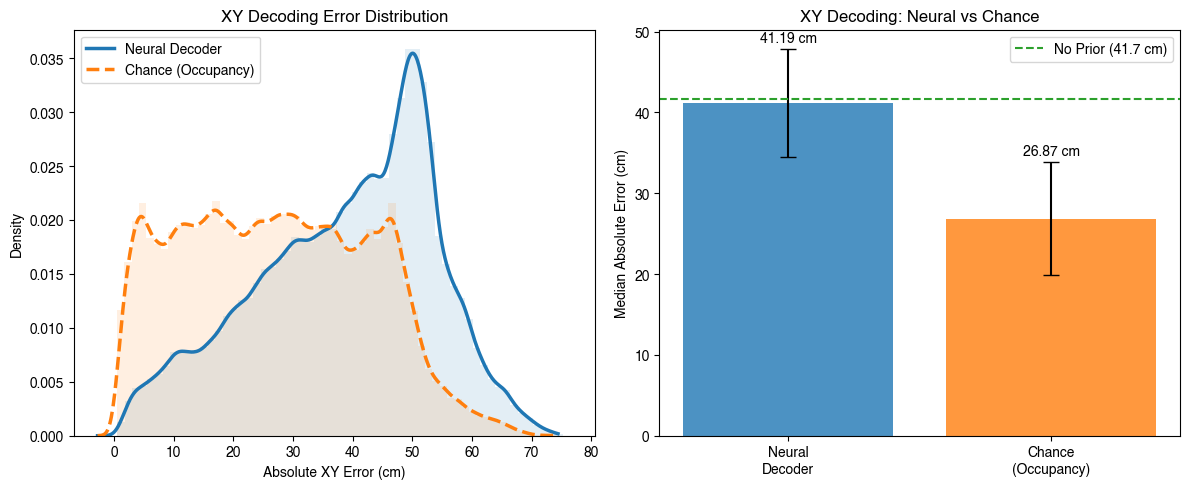

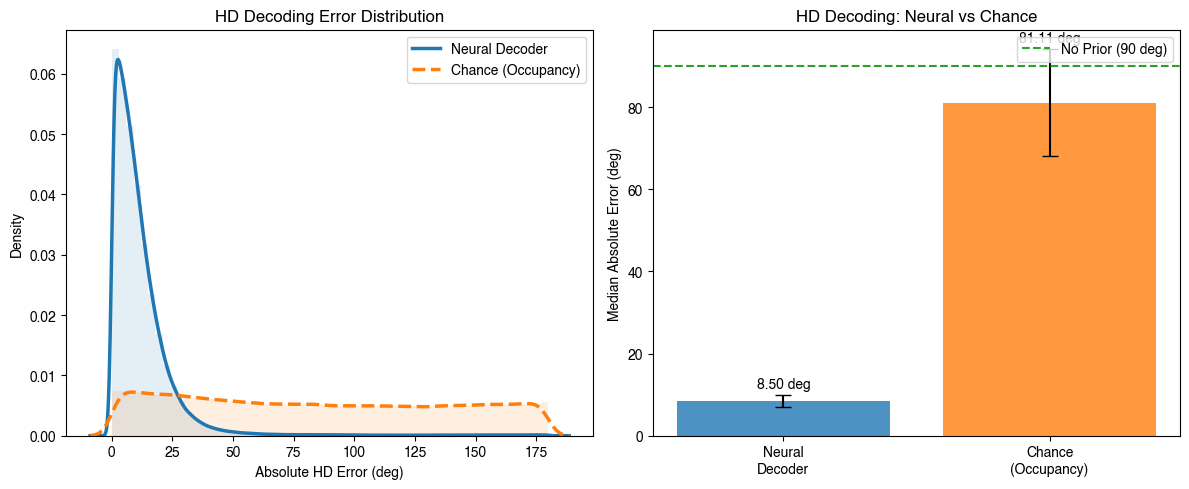

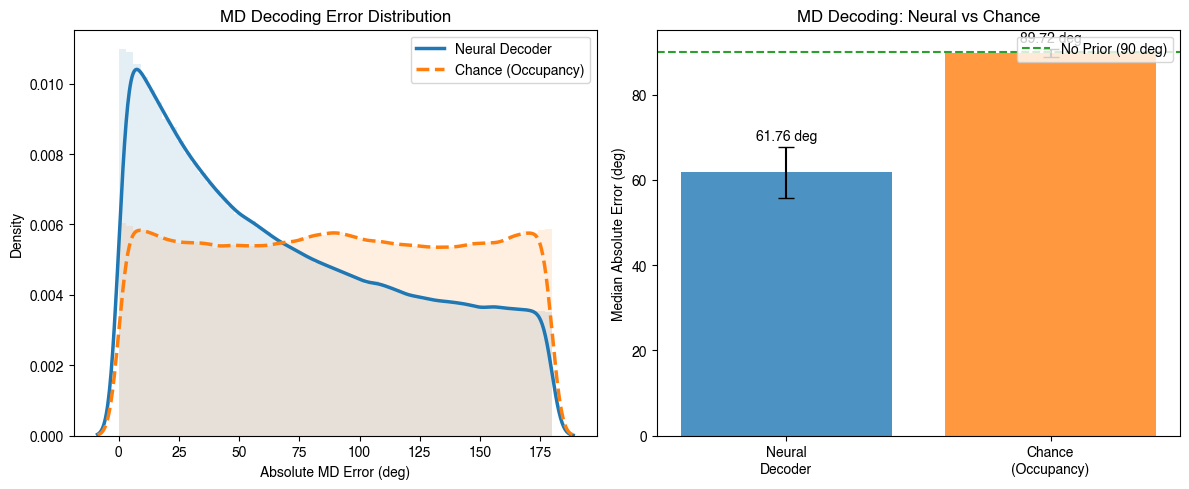

In [7]:
from tqdm import tqdm

# ============ Configuration ============
root = save_path
bins = 60
density = True
min_xy_cm = 0.5
env_size_cm = 80.0
xy_grid = 32
hd_bins = 360

# No-prior chance values (uniform random guessing)
import math
sqrt2 = math.sqrt(2)
NO_PRIOR_XY_COEFF = (2 + sqrt2 + 5 * math.log(1 + sqrt2)) / 15  # ~0.5214
NO_PRIOR_XY_CM = NO_PRIOR_XY_COEFF * env_size_cm  # ~41.71 cm for 80cm arena
NO_PRIOR_HD_DEG = 90.0  # Expected error for uniform guessing over [0, 360)
NO_PRIOR_MD_DEG = 90.0  # Same for movement direction

# ============ Imports ============
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import gaussian_kde

# ============ Load data ============
rats = sorted(
    {p.parent for p in root.rglob("errors_xy_cv*_32x32_all.npz")} |
    {p.parent for p in root.rglob("errors_hd_cv*_360_all.npz")} |
    {p.parent for p in root.rglob("errors_md_cv*_360_all.npz")}
)

precomp = []
for rat in tqdm(rats):
    # Neural decoding files
    xfiles = list(rat.glob("errors_xy_cv*_32x32_all.npz"))
    hfiles = list(rat.glob("errors_hd_cv*_360_all.npz"))
    mfiles = list(rat.glob("errors_md_cv*_360_all.npz"))

    # Chance decoding files
    xfiles_chance = list(rat.glob("errors_xy_chance_cv*_32x32_all.npz"))
    hfiles_chance = list(rat.glob("errors_hd_chance_cv*_360_all.npz"))
    mfiles_chance = list(rat.glob("errors_md_chance_cv*_360_all.npz"))

    if not xfiles or not hfiles:
        continue

    # Load XY neural decoding errors
    xy = []
    for f in xfiles:
        d = np.load(f, allow_pickle=True)
        a = np.asarray(d["errors"]).ravel()
        a = a[np.isfinite(a)]
        a = a[a >= min_xy_cm]
        if a.size:
            xy.append(a)

    xy_chance = []
    for f in xfiles_chance:
        d = np.load(f, allow_pickle=True)
        a = np.asarray(d["errors"]).ravel()
        a = a[np.isfinite(a)]
        a = a[a >= min_xy_cm]
        if a.size:
            xy_chance.append(a)

    hd = []
    for f in hfiles:
        d = np.load(f, allow_pickle=True)
        a = np.asarray(d["errors_deg"]).ravel()
        a = np.abs(a[~np.isnan(a)])
        if a.size:
            hd.append(a)

    hd_chance = []
    for f in hfiles_chance:
        d = np.load(f, allow_pickle=True)
        a = np.asarray(d["errors_deg"]).ravel()
        a = np.abs(a[~np.isnan(a)])
        if a.size:
            hd_chance.append(a)

    # Load MD neural decoding errors
    md = []
    for f in mfiles:
        d = np.load(f, allow_pickle=True)
        a = np.asarray(d["errors_deg"]).ravel()
        a = np.abs(a[~np.isnan(a)])
        if a.size:
            md.append(a)

    md_chance = []
    for f in mfiles_chance:
        d = np.load(f, allow_pickle=True)
        a = np.asarray(d["errors_deg"]).ravel()
        a = np.abs(a[~np.isnan(a)])
        if a.size:
            md_chance.append(a)

    if xy and hd:
        entry = {
            "xy": np.concatenate(xy),
            "hd": np.concatenate(hd),
        }
        if xy_chance:
            entry["xy_chance"] = np.concatenate(xy_chance)
        if hd_chance:
            entry["hd_chance"] = np.concatenate(hd_chance)
        if md:
            entry["md"] = np.concatenate(md)
        if md_chance:
            entry["md_chance"] = np.concatenate(md_chance)
        precomp.append(entry)

all_xy = np.concatenate([d["xy"] for d in precomp])
all_hd = np.concatenate([d["hd"] for d in precomp])

has_xy_chance = all("xy_chance" in d for d in precomp)
has_hd_chance = all("hd_chance" in d for d in precomp)
has_md = any("md" in d for d in precomp)
has_md_chance = any("md_chance" in d for d in precomp)

if has_xy_chance:
    all_xy_chance = np.concatenate([d["xy_chance"] for d in precomp])
else:
    all_xy_chance = None
    print("Warning: XY chance decoding data not found")

if has_hd_chance:
    all_hd_chance = np.concatenate([d["hd_chance"] for d in precomp])
else:
    all_hd_chance = None
    print("Warning: HD chance decoding data not found")

if has_md:
    all_md = np.concatenate([d["md"] for d in precomp if "md" in d])
else:
    all_md = None
    print("Warning: MD decoding data not found")

if has_md_chance:
    all_md_chance = np.concatenate([d["md_chance"] for d in precomp if "md_chance" in d])
else:
    all_md_chance = None

# ============ XY Decoding ============
fig_xy, axs_xy = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: KDE comparison
if all_xy.size:
    if all_xy_chance is not None and all_xy_chance.size:
        _xy_for_range = np.concatenate([all_xy, all_xy_chance])
    else:
        _xy_for_range = all_xy

    _xy_for_range = _xy_for_range[np.isfinite(_xy_for_range)]
    qlo, qhi = np.quantile(_xy_for_range, [0.001, 0.999])
    if not np.isfinite(qlo) or not np.isfinite(qhi) or qhi <= qlo:
        qlo, qhi = float(np.nanmin(_xy_for_range)), float(np.nanmax(_xy_for_range))

    pad = 0.05 * (qhi - qlo) if qhi > qlo else 1.0
    xs_xy = np.linspace(qlo - pad, qhi + pad, 600)

    # (Optional) faint hist fill for context — remove if you want only KDE lines
    axs_xy[0].hist(all_xy, bins=bins, density=density, alpha=0.12, color="C0", edgecolor="none")
    if all_xy_chance is not None:
        axs_xy[0].hist(all_xy_chance, bins=bins, density=density, alpha=0.12, color="C1", edgecolor="none")

    kde_xy = gaussian_kde(all_xy[np.isfinite(all_xy)])
    axs_xy[0].plot(xs_xy, kde_xy(xs_xy), color="C0", linewidth=2.5, label="Neural Decoder")

    if all_xy_chance is not None and np.isfinite(all_xy_chance).any() and all_xy_chance.size > 1:
        kde_xy_ch = gaussian_kde(all_xy_chance[np.isfinite(all_xy_chance)])
        axs_xy[0].plot(xs_xy, kde_xy_ch(xs_xy), color="C1", linewidth=2.5, linestyle="--",
                       label="Chance (Occupancy)")

axs_xy[0].set_xlabel("Absolute XY Error (cm)")
axs_xy[0].set_ylabel("Density" if density else "Count")
axs_xy[0].set_title("XY Decoding Error Distribution")
axs_xy[0].legend()

xy_median_neural = float(np.nanmedian(all_xy))
xy_median_chance = float(np.nanmedian(all_xy_chance)) if all_xy_chance is not None else 0

rat_xy_neural = np.array([np.nanmedian(d["xy"]) for d in precomp])
rat_xy_chance = np.array([np.nanmedian(d["xy_chance"]) for d in precomp if "xy_chance" in d])

xy_std_neural = float(np.nanstd(rat_xy_neural, ddof=1)) if len(rat_xy_neural) > 1 else 0
xy_std_chance = float(np.nanstd(rat_xy_chance, ddof=1)) if len(rat_xy_chance) > 1 else 0

bar_labels = ["Neural\nDecoder", "Chance\n(Occupancy)"]
bar_values = [xy_median_neural, xy_median_chance]
bar_errors = [xy_std_neural, xy_std_chance]
bar_colors = ["C0", "C1"]

bars = axs_xy[1].bar([0, 1], bar_values, yerr=bar_errors, capsize=6,
                     alpha=0.8, color=bar_colors)
axs_xy[1].set_xticks([0, 1])
axs_xy[1].set_xticklabels(bar_labels)
axs_xy[1].set_ylabel("Median Absolute Error (cm)")
axs_xy[1].set_title("XY Decoding: Neural vs Chance")

# Add no-prior chance reference line
axs_xy[1].axhline(y=NO_PRIOR_XY_CM, color="C2", linestyle="--", linewidth=1.5,
                  label=f"No Prior ({NO_PRIOR_XY_CM:.1f} cm)")
axs_xy[1].legend(loc="upper right")

# Add value labels on bars
for i, (val, err) in enumerate(zip(bar_values, bar_errors)):
    axs_xy[1].text(i, val + err + 0.5, f"{val:.2f} cm",
                   ha="center", va="bottom", fontsize=10)
fig_xy.tight_layout()

# ============ HD Decoding ============
fig_hd, axs_hd = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: KDE comparison
if all_hd.size:
    if all_hd_chance is not None and all_hd_chance.size:
        _hd_for_range = np.concatenate([all_hd, all_hd_chance])
    else:
        _hd_for_range = all_hd

    _hd_for_range = _hd_for_range[np.isfinite(_hd_for_range)]
    qlo, qhi = np.quantile(_hd_for_range, [0.001, 0.999])
    if not np.isfinite(qlo) or not np.isfinite(qhi) or qhi <= qlo:
        qlo, qhi = float(np.nanmin(_hd_for_range)), float(np.nanmax(_hd_for_range))

    pad = 0.05 * (qhi - qlo) if qhi > qlo else 1.0
    xs_hd = np.linspace(qlo - pad, qhi + pad, 600)

    # (Optional) faint hist fill for context — remove if you want only KDE lines
    axs_hd[0].hist(all_hd, bins=bins, density=density, alpha=0.12, color="C0", edgecolor="none")
    if all_hd_chance is not None:
        axs_hd[0].hist(all_hd_chance, bins=bins, density=density, alpha=0.12, color="C1", edgecolor="none")

    kde_hd = gaussian_kde(all_hd[np.isfinite(all_hd)])
    axs_hd[0].plot(xs_hd, kde_hd(xs_hd), color="C0", linewidth=2.5, label="Neural Decoder")

    if all_hd_chance is not None and np.isfinite(all_hd_chance).any() and all_hd_chance.size > 1:
        kde_hd_ch = gaussian_kde(all_hd_chance[np.isfinite(all_hd_chance)])
        axs_hd[0].plot(xs_hd, kde_hd_ch(xs_hd), color="C1", linewidth=2.5, linestyle="--",
                       label="Chance (Occupancy)")

axs_hd[0].set_xlabel("Absolute HD Error (deg)")
axs_hd[0].set_ylabel("Density" if density else "Count")
axs_hd[0].set_title("HD Decoding Error Distribution")
axs_hd[0].legend()

hd_median_neural = float(np.nanmedian(all_hd))
hd_median_chance = float(np.nanmedian(all_hd_chance)) if all_hd_chance is not None else 0

rat_hd_neural = np.array([np.nanmedian(d["hd"]) for d in precomp])
rat_hd_chance = np.array([np.nanmedian(d["hd_chance"]) for d in precomp if "hd_chance" in d])

hd_std_neural = float(np.nanstd(rat_hd_neural, ddof=1)) if len(rat_hd_neural) > 1 else 0
hd_std_chance = float(np.nanstd(rat_hd_chance, ddof=1)) if len(rat_hd_chance) > 1 else 0

bar_labels = ["Neural\nDecoder", "Chance\n(Occupancy)"]
bar_values = [hd_median_neural, hd_median_chance]
bar_errors = [hd_std_neural, hd_std_chance]
bar_colors = ["C0", "C1"]

bars = axs_hd[1].bar([0, 1], bar_values, yerr=bar_errors, capsize=6,
                     alpha=0.8, color=bar_colors)
axs_hd[1].set_xticks([0, 1])
axs_hd[1].set_xticklabels(bar_labels)
axs_hd[1].set_ylabel("Median Absolute Error (deg)")
axs_hd[1].set_title("HD Decoding: Neural vs Chance")

# Add no-prior chance reference line
axs_hd[1].axhline(y=NO_PRIOR_HD_DEG, color="C2", linestyle="--", linewidth=1.5,
                  label=f"No Prior ({NO_PRIOR_HD_DEG:.0f} deg)")
axs_hd[1].legend(loc="upper right")

for i, (val, err) in enumerate(zip(bar_values, bar_errors)):
    axs_hd[1].text(i, val + err + 1, f"{val:.2f} deg",
                   ha="center", va="bottom", fontsize=10)

fig_hd.tight_layout()

# ============ MD Decoding ============
if all_md is not None:
    fig_md, axs_md = plt.subplots(1, 2, figsize=(12, 5))

    # Subplot 1: KDE comparison
    if all_md.size:
        if all_md_chance is not None and all_md_chance.size:
            _md_for_range = np.concatenate([all_md, all_md_chance])
        else:
            _md_for_range = all_md

        _md_for_range = _md_for_range[np.isfinite(_md_for_range)]
        qlo, qhi = np.quantile(_md_for_range, [0.001, 0.999])
        if not np.isfinite(qlo) or not np.isfinite(qhi) or qhi <= qlo:
            qlo, qhi = float(np.nanmin(_md_for_range)), float(np.nanmax(_md_for_range))

        pad = 0.05 * (qhi - qlo) if qhi > qlo else 1.0
        xs_md = np.linspace(qlo - pad, qhi + pad, 600)

        # (Optional) faint hist fill for context — remove if you want only KDE lines
        axs_md[0].hist(all_md, bins=bins, density=density, alpha=0.12, color="C0", edgecolor="none")
        if all_md_chance is not None:
            axs_md[0].hist(all_md_chance, bins=bins, density=density, alpha=0.12, color="C1", edgecolor="none")

        kde_md = gaussian_kde(all_md[np.isfinite(all_md)])
        axs_md[0].plot(xs_md, kde_md(xs_md), color="C0", linewidth=2.5, label="Neural Decoder")

        if all_md_chance is not None and np.isfinite(all_md_chance).any() and all_md_chance.size > 1:
            kde_md_ch = gaussian_kde(all_md_chance[np.isfinite(all_md_chance)])
            axs_md[0].plot(xs_md, kde_md_ch(xs_md), color="C1", linewidth=2.5, linestyle="--",
                           label="Chance (Occupancy)")

    axs_md[0].set_xlabel("Absolute MD Error (deg)")
    axs_md[0].set_ylabel("Density" if density else "Count")
    axs_md[0].set_title("MD Decoding Error Distribution")
    axs_md[0].legend()

    md_median_neural = float(np.nanmedian(all_md))
    md_median_chance = float(np.nanmedian(all_md_chance)) if all_md_chance is not None else 0

    rat_md_neural = np.array([np.nanmedian(d["md"]) for d in precomp if "md" in d])
    rat_md_chance = np.array([np.nanmedian(d["md_chance"]) for d in precomp if "md_chance" in d])

    md_std_neural = float(np.nanstd(rat_md_neural, ddof=1)) if len(rat_md_neural) > 1 else 0
    md_std_chance = float(np.nanstd(rat_md_chance, ddof=1)) if len(rat_md_chance) > 1 else 0

    bar_labels = ["Neural\nDecoder", "Chance\n(Occupancy)"]
    bar_values = [md_median_neural, md_median_chance]
    bar_errors = [md_std_neural, md_std_chance]
    bar_colors = ["C0", "C1"]

    bars = axs_md[1].bar([0, 1], bar_values, yerr=bar_errors, capsize=6,
                         alpha=0.8, color=bar_colors)
    axs_md[1].set_xticks([0, 1])
    axs_md[1].set_xticklabels(bar_labels)
    axs_md[1].set_ylabel("Median Absolute Error (deg)")
    axs_md[1].set_title("MD Decoding: Neural vs Chance")

    # Add no-prior chance reference line
    axs_md[1].axhline(y=NO_PRIOR_MD_DEG, color="C2", linestyle="--", linewidth=1.5,
                      label=f"No Prior ({NO_PRIOR_MD_DEG:.0f} deg)")
    axs_md[1].legend(loc="upper right")

    for i, (val, err) in enumerate(zip(bar_values, bar_errors)):
        axs_md[1].text(i, val + err + 1, f"{val:.2f} deg",
                       ha="center", va="bottom", fontsize=10)

    fig_md.tight_layout()

# ============ Save figures ============
Path("figs").mkdir(parents=True, exist_ok=True)
fig_xy.savefig("figs/dusz_xy_decoding_vs_chance.pdf", dpi=300)
fig_hd.savefig("figs/dusz_hd_decoding_vs_chance.pdf", dpi=300)
print("Saved: figs/dusz_xy_decoding_vs_chance.pdf")
print("Saved: figs/dusz_hd_decoding_vs_chance.pdf")

if all_md is not None:
    fig_md.savefig("figs/dusz_md_decoding_vs_chance.pdf", dpi=300)
    print("Saved: figs/dusz_md_decoding_vs_chance.pdf")

plt.show()


## Plot individual error histograms.

In [8]:
from pathlib import Path
from typing import Dict, List, Optional, Literal
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import math
from scipy.stats import gaussian_kde

# ============Configuration ============
dataset = "dusz"  # "pfeiffer" or "dusz"
mode = "hd_md"    # "xy_hd" or "hd_md" (hd_md only for dusz)
# save_path = Path("./results/pfeiffer")  # for pfeiffer
# save_path already defined in notebook for dusz

use_median = True
bins = 60
min_neurons = 40

# No-prior chance values (uniform random guessing)
sqrt2 = math.sqrt(2)
NO_PRIOR_XY_COEFF = (2 + sqrt2 + 5 * math.log(1 + sqrt2)) / 15  # ~0.5214
# Environment sizes
PFEIFFER_ENV_CM = 200.0
DUSZ_ENV_CM = 80.0
NO_PRIOR_XY_PFEIFFER = NO_PRIOR_XY_COEFF * PFEIFFER_ENV_CM  # ~104.28 cm
NO_PRIOR_XY_DUSZ = NO_PRIOR_XY_COEFF * DUSZ_ENV_CM  # ~41.71 cm
NO_PRIOR_HD_DEG = 90.0  # Expected error for uniform guessing over [0, 360)
NO_PRIOR_MD_DEG = 90.0  # Same for movement direction

# ============ Helpers ============

def plot_error_comparison(ax_hist, ax_bar, errors_neural, errors_chance, label, unit, no_prior_val=None):
    # ---- KDE plot (replaces histogram bars) ----
    errors_neural = np.asarray(errors_neural)
    errors_neural = errors_neural[np.isfinite(errors_neural)]
    errors_ch = None
    if errors_chance is not None and len(errors_chance) > 0:
        errors_ch = np.asarray(errors_chance)
        errors_ch = errors_ch[np.isfinite(errors_ch)]

    if errors_ch is not None and errors_ch.size:
        _for_range = np.concatenate([errors_neural, errors_ch])
    else:
        _for_range = errors_neural

    if _for_range.size:
        qlo, qhi = np.quantile(_for_range, [0.001, 0.999])
        if not np.isfinite(qlo) or not np.isfinite(qhi) or qhi <= qlo:
            qlo, qhi = float(np.nanmin(_for_range)), float(np.nanmax(_for_range))

        pad = 0.05 * (qhi - qlo) if qhi > qlo else 1.0
        xs = np.linspace(qlo - pad, qhi + pad, 600)

        # (Optional) faint hist fill for context — delete these lines if you want KDE-only
        ax_hist.hist(errors_neural, bins=bins, density=True, alpha=0.12, color="C0", edgecolor="none")
        if errors_ch is not None:
            ax_hist.hist(errors_ch, bins=bins, density=True, alpha=0.12, color="C1", edgecolor="none")

        kde_n = gaussian_kde(errors_neural)
        ax_hist.plot(xs, kde_n(xs), color="C0", linewidth=2.5, label="Neural Decoder")

        if errors_ch is not None and errors_ch.size > 1:
            kde_c = gaussian_kde(errors_ch)
            ax_hist.plot(xs, kde_c(xs), color="C1", linewidth=2.5, linestyle="--", label="Chance (Occupancy)")

    ax_hist.set_xlabel(f"Absolute {label} Error ({unit})")
    ax_hist.set_ylabel("Density")
    ax_hist.set_title(f"{label} Error Distribution")
    ax_hist.legend()

    # ---- bar plot (unchanged logic, but handle None safely) ----
    stat_fn = np.nanmedian if use_median else np.nanmean
    neural_val = float(stat_fn(errors_neural)) if errors_neural.size else 0.0
    chance_val = float(stat_fn(errors_ch)) if (errors_ch is not None and errors_ch.size) else 0.0

    ax_bar.bar([0, 1], [neural_val, chance_val], alpha=0.8, color=["C0", "C1"])
    ax_bar.set_xticks([0, 1])
    ax_bar.set_xticklabels(["Neural", "Chance"])
    ax_bar.set_ylabel(f"{'Median' if use_median else 'Mean'} Error ({unit})")
    ax_bar.set_title(f"{label}: Neural vs Chance")

    # Add no-prior chance reference line if provided
    if no_prior_val is not None:
        ax_bar.axhline(y=no_prior_val, color="C2", linestyle="--", linewidth=1.5,
                       label=f"No Prior ({no_prior_val:.1f})")
        ax_bar.legend(loc="upper right")

    # Value labels
    denom = max(neural_val, chance_val, 1e-9)
    for i, val in enumerate([neural_val, chance_val]):
        ax_bar.text(i, val + denom * 0.05, f"{val:.2f}{unit}", ha="center", va="bottom")


def load_errors(files, key="errors_deg", take_abs=True):
    arrays = []
    for f in files:
        try:
            arr = np.asarray(np.load(f, allow_pickle=True)[key]).ravel()
            arr = arr[np.isfinite(arr)]
            if take_abs:
                arr = np.abs(arr)
            if key == 'errors' or key == 'errors_cm':
                arr = arr[arr > 0.2]
            if arr.size > 0:
                arrays.append(arr)
        except:
            pass
    return np.concatenate(arrays) if arrays else None


# ============ Discover sessions ============

sessions = []

if dataset == "pfeiffer":
    rat_dirs = sorted({f.parent for f in save_path.rglob("errors_xy_cv*_*x*.npz")} |
                      {f.parent for f in save_path.rglob("errors_hd_cv*_*.npz")})

    for dpath in rat_dirs:
        name = dpath.relative_to(save_path).as_posix()
        xy_neural = load_errors([f for f in dpath.glob("errors_xy_cv*_*x*.npz") if "chance" not in f.name], key="errors_cm")
        xy_chance = load_errors(list(dpath.glob("errors_xy_chance_cv*_*x*.npz")), key="errors_cm")
        hd_neural = load_errors([f for f in dpath.glob("errors_hd_cv*_*.npz") if "chance" not in f.name], key="errors_deg")
        hd_chance = load_errors(list(dpath.glob("errors_hd_chance_cv*_*.npz")), key="errors_deg")

        if xy_neural is not None or hd_neural is not None:
            sessions.append({
                'name': name, 'var1': xy_neural, 'var1_c': xy_chance, 'var2': hd_neural, 'var2_c': hd_chance,
                'l1': 'XY', 'u1': 'cm', 'l2': 'HD', 'u2': 'deg',
                'no_prior_1': NO_PRIOR_XY_PFEIFFER, 'no_prior_2': NO_PRIOR_HD_DEG
            })

else:  # dusz
    if mode == "xy_hd":
        rat_dirs = sorted({f.parent for f in save_path.rglob("errors_xy_cv*_*x*_all.npz")} |
                          {f.parent for f in save_path.rglob("errors_hd_cv*_*_all.npz")})
    else:
        rat_dirs = sorted({f.parent for f in save_path.rglob("errors_hd_cv*_*_all.npz")} |
                          {f.parent for f in save_path.rglob("errors_md_cv*_*_all.npz")})

    for dpath in rat_dirs:
        name = dpath.relative_to(save_path).as_posix()

        if min_neurons > 0:
            kept_path = dpath / "neurons_kept_hd_filter.npy"
            if kept_path.exists():
                try:
                    n = float(np.unique(np.load(kept_path, allow_pickle=True)).size)
                    if n < min_neurons:
                        continue
                except:
                    pass

        if mode == "xy_hd":
            var1 = load_errors([f for f in dpath.glob("errors_xy_cv*_*x*_all.npz") if "chance" not in f.name], key="errors")
            var1_c = load_errors(list(dpath.glob("errors_xy_chance_cv*_*x*_all.npz")), key="errors")
            var2 = load_errors([f for f in dpath.glob("errors_hd_cv*_*_all.npz") if "chance" not in f.name], key="errors_deg")
            var2_c = load_errors(list(dpath.glob("errors_hd_chance_cv*_*_all.npz")), key="errors_deg")
            l1, u1, l2, u2 = "XY", "cm", "HD", "deg"
            no_prior_1, no_prior_2 = NO_PRIOR_XY_DUSZ, NO_PRIOR_HD_DEG
        else:
            var1 = load_errors([f for f in dpath.glob("errors_hd_cv*_*_all.npz") if "chance" not in f.name], key="errors_deg")
            var1_c = load_errors(list(dpath.glob("errors_hd_chance_cv*_*_all.npz")), key="errors_deg")
            var2 = load_errors([f for f in dpath.glob("errors_md_cv*_*_all.npz") if "chance" not in f.name], key="errors_deg")
            var2_c = load_errors(list(dpath.glob("errors_md_chance_cv*_*_all.npz")), key="errors_deg")
            l1, u1, l2, u2 = "HD", "deg", "MD", "deg"
            no_prior_1, no_prior_2 = NO_PRIOR_HD_DEG, NO_PRIOR_MD_DEG

        if var1 is not None or var2 is not None:
            sessions.append({'name': name, 'var1': var1, 'var1_c': var1_c, 'var2': var2, 'var2_c': var2_c,
                             'l1': l1, 'u1': u1, 'l2': l2, 'u2': u2,
                             'no_prior_1': no_prior_1, 'no_prior_2': no_prior_2})

print(f"Found {len(sessions)} sessions")

# ============ Generate PDF ============

output_dir = save_path / "figs"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{dataset}_{mode}_individual_sessions.pdf"

with PdfPages(output_path) as pdf:
    for i, s in enumerate(sessions):
        print(f"  [{i+1}/{len(sessions)}] {s['name']}")

        if s['var1'] is None and s['var2'] is None:
            continue

        fig, axs = plt.subplots(2, 2, figsize=(12, 10))
        fig.suptitle(s['name'], fontsize=14, fontweight='bold')

        if s['var1'] is not None and len(s['var1']) > 0:
            plot_error_comparison(axs[0, 0], axs[0, 1], s['var1'], s.get('var1_c'), s['l1'], s['u1'], s.get('no_prior_1'))
        if s['var2'] is not None and len(s['var2']) > 0:
            plot_error_comparison(axs[1, 0], axs[1, 1], s['var2'], s.get('var2_c'), s['l2'], s['u2'], s.get('no_prior_2'))

        fig.tight_layout(rect=[0, 0, 1, 0.96])
        pdf.savefig(fig, dpi=150)
        plt.close(fig)

print(f"\nSaved: {output_path}")


Found 15 sessions
  [1/15] Dataset_1/A3701-191119
  [2/15] Dataset_1/A3702-191126
  [3/15] Dataset_1/A3703-191215
  [4/15] Dataset_1/A3705-200306
  [5/15] Dataset_1/A3706-200313
  [6/15] Dataset_1/A3707-200317
  [7/15] Dataset_1/A3708-200317b
  [8/15] Dataset_1/A3710-200609
  [9/15] Dataset_1/A3711-200810b
  [10/15] Dataset_1/A3712-200903a
  [11/15] Dataset_1/A3716-201015b
  [12/15] Dataset_1/A3717-201021
  [13/15] Dataset_1/A3730-210323b
  [14/15] Dataset_2/A5507-200920
  [15/15] Dataset_2/A6216-210623

Saved: /content/drive/MyDrive/ve/variance_analysis/results/rodents/dusz/figs/dusz_hd_md_individual_sessions.pdf


### extra: count the hd neurons and store

In [ ]:
# %% [markdown]
# Collect a dictionary of session titles -> HD neuron counts for Dusz dataset

# %%
from pathlib import Path
import numpy as np
from scipy.io import loadmat

# -- robust MATLAB struct extractor (matches your pipeline) --
def _extract_matlab_obj(obj):
    try:
        from scipy.io.matlab._mio5_params import mat_struct
    except Exception:
        mat_struct = ()  # fallback if internal path changes
    if not (isinstance(obj, dict) or isinstance(obj, mat_struct)):
        return obj
    d = obj.__dict__ if hasattr(obj, "__dict__") else obj
    out = {}
    for k, v in d.items():
        if k in ["_fieldnames", "type", "time_unit", "data_unit", "name"]:
            continue
        if hasattr(v, "__dict__") or isinstance(v, dict):
            out[k] = _extract_matlab_obj(v)
        elif isinstance(v, np.ndarray):
            out[k] = np.array([_extract_matlab_obj(x) for x in v])
        else:
            out[k] = v
    return out

def _to_1d_int(arr):
    a = np.asarray(arr).ravel()
    # convert booleans or truthy to ints
    if a.dtype == bool:
        a = a.astype(int)
    return a.astype(int, copy=False)

def count_hd_neurons(celltypes_mat_path: Path) -> int:
    """Return number of HD neurons (hd == 1) from a Dusz CellTypes.mat file."""
    ct_raw = loadmat(celltypes_mat_path, struct_as_record=False, squeeze_me=True)
    # Commonly the struct is under 'CellTypes', but support variants.
    ct = _extract_matlab_obj(ct_raw.get('CellTypes', ct_raw))
    # Try several likely places for the hd vector
    candidates = [
        ct.get('hd'),
        ct_raw.get('hd'),
        (ct.get('labels', {}) if isinstance(ct.get('labels'), dict) else {}).get('hd'),
    ]
    hd_vec = None
    for c in candidates:
        if c is not None and np.size(c) > 0:
            hd_vec = _to_1d_int(c)
            break
    if hd_vec is None:
        raise FileNotFoundError(f"Couldn't find 'hd' labels in {celltypes_mat_path}")
    # Convention: hd == 1 means HD cell
    return int(np.sum(hd_vec == 1))

def gather_hd_counts(
    data_root: Path = Path("./data/dusz"),
    sessions: list[tuple[int, str]] | None = None,
) -> dict[str, int]:
    """
    Build { 'Dataset_{id}/RAT': hd_count }.
    If `sessions` is None, auto-discovers all Dataset_*/*/Data/CellTypes.mat.
    """
    results: dict[str, int] = {}
    if sessions is None:
        for ct_path in sorted(data_root.glob("Dataset_*/*/Data/CellTypes.mat")):
            dataset_str = ct_path.parts[-4]  # "Dataset_{id}"
            rat = ct_path.parts[-3]
            title = f"{dataset_str}/{rat}"
            try:
                results[title] = count_hd_neurons(ct_path)
            except Exception as e:
                results[title] = -1  # mark failure
    else:
        for ds_id, rat in sessions:
            ct_path = data_root / f"Dataset_{ds_id}" / rat / "Data" / "CellTypes.mat"
            title = f"Dataset_{ds_id}/{rat}"
            try:
                results[title] = count_hd_neurons(ct_path)
            except Exception:
                results[title] = -1
    return results


hd_counts = gather_hd_counts(Path(data_path), sessions=session_list)

# Print the dictionary (and a neat summary)
print(hd_counts)
print("\nSummary:")
ok = {k: v for k, v in hd_counts.items() if v >= 0}
fail = [k for k, v in hd_counts.items() if v < 0]
print(f"  Sessions found: {len(hd_counts)}")
print(f"  With counts    : {len(ok)} (total HD neurons = {sum(ok.values())})")
if fail:
    print(f"  Failed to read : {len(fail)} -> {fail}")


import json
from pathlib import Path

# --- after computing hd_counts ---
output_path = Path(save_path / "hd_neuron_counts.json")

# Save dictionary to JSON
with open(output_path, "w") as f:
    json.dump(hd_counts, f, indent=2)  # indent makes it nicely formatted

print(f"Saved HD counts to {output_path}")

# --- later on, when you want to load it ---
with open(output_path, "r") as f:
    loaded_hd_counts = json.load(f)

print("Loaded HD counts:", loaded_hd_counts)



{'Dataset_1/A3701-191119': 71, 'Dataset_1/A3702-191126': 61, 'Dataset_1/A3703-191215': 65, 'Dataset_1/A3705-200306': 66, 'Dataset_1/A3706-200313': 86, 'Dataset_1/A3707-200317': 117, 'Dataset_1/A3708-200317b': 44, 'Dataset_1/A3709-200601': 21, 'Dataset_1/A3710-200609': 80, 'Dataset_1/A3711-200810b': 90, 'Dataset_1/A3712-200903a': 73, 'Dataset_1/A3713-200909a': 25, 'Dataset_1/A3716-201015b': 93, 'Dataset_1/A3717-201021': 59, 'Dataset_1/A3723-201115': 37, 'Dataset_1/A3728-210309b': 27, 'Dataset_1/A3730-210323b': 47, 'Dataset_2/A1808-190807': 29, 'Dataset_2/A1813-190408': 30, 'Dataset_2/A1815-190523': 33, 'Dataset_2/A1821-190910': 37, 'Dataset_2/A1824-190827': 39, 'Dataset_2/A5505-200831': 30, 'Dataset_2/A5506-200914a': 24, 'Dataset_2/A5507-200920': 43, 'Dataset_2/A5508-200930': 33, 'Dataset_2/A5801-200924': 26, 'Dataset_2/A6211-210407': 36, 'Dataset_2/A6215-210610': 29, 'Dataset_2/A6216-210623': 44, 'Dataset_2/A9701-210805': 38}

Summary:
  Sessions found: 31
  With counts    : 31 (total 